In [54]:
# %%
"""
Before running this script, make sure that you have run the following commands:
- make download-dataset # download the dataset
- make unzip-dataset # unzip the dataset
- make pip-install # install the required packages
"""

'\nBefore running this script, make sure that you have run the following commands:\n- make download-dataset # download the dataset\n- make unzip-dataset # unzip the dataset\n- make pip-install # install the required packages\n'

In [55]:
# %%
import os
import re

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image


In [56]:
# %%

try:
    # If running in Jupyter, this will return an IPython instance
    get_ipython()
    in_jupyter = True
except NameError:
    in_jupyter = False

path_to_root = os.path.join(os.getcwd(), "..") if in_jupyter else os.getcwd()



In [57]:
# %%
def create_dataset_df():
    dirs_with_real_images = ["images/wiki"]
    dirs_with_fake_images = ["images/inpainting", "images/insight", "images/text2img"]

    # image regex for images that end with jpg, jpeg, or png
    image_regex = r".*\.(jpg|jpeg|png)$"

    # read real image paths and store them in a DataFrame
    real_image_paths = []
    for _dir in dirs_with_real_images:
        for root, _, files in os.walk(os.path.join(path_to_root, _dir)):
            for file in files:
                if re.match(image_regex, file):
                    real_image_paths.append(os.path.join(root, file))

    real_image_df = pd.DataFrame(real_image_paths, columns=["image_path"])
    real_image_df["image_type"] = "real"
    real_image_df["label"] = 1

    # read fake image paths and store them in a DataFrame
    fake_image_paths = []
    for _dir in dirs_with_fake_images:
        for root, _, files in os.walk(os.path.join(path_to_root, _dir)):
            for file in files:
                if re.match(image_regex, file):
                    fake_image_paths.append(os.path.join(root, file))

    fake_image_df = pd.DataFrame(fake_image_paths, columns=["image_path"])
    fake_image_df["image_type"] = "fake"
    fake_image_df["label"] = 0

    # combine the real and fake image DataFrames
    return pd.concat([real_image_df, fake_image_df], ignore_index=True)



In [58]:
# %%
dataset_df = create_dataset_df()


In [59]:
# %%
if in_jupyter:
    dataset_df.head()

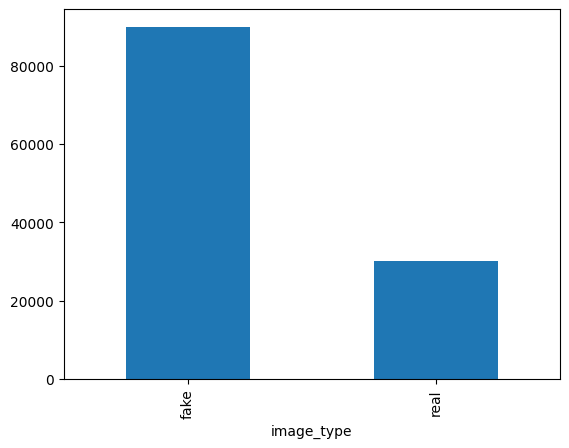

In [60]:
# %%
if in_jupyter:
    # plot the distribution of real and fake images
    dataset_df["image_type"].value_counts().plot(kind="bar")

In [61]:
# %%
print(dataset_df["image_type"].value_counts())


image_type
fake    90000
real    30000
Name: count, dtype: int64


In [62]:
# %%
# print image dimensions
for image_path in dataset_df["image_path"].sample(5):
    image = Image.open(image_path)
    print(image.size)

(440, 230)
(512, 512)
(512, 512)
(512, 512)
(440, 658)


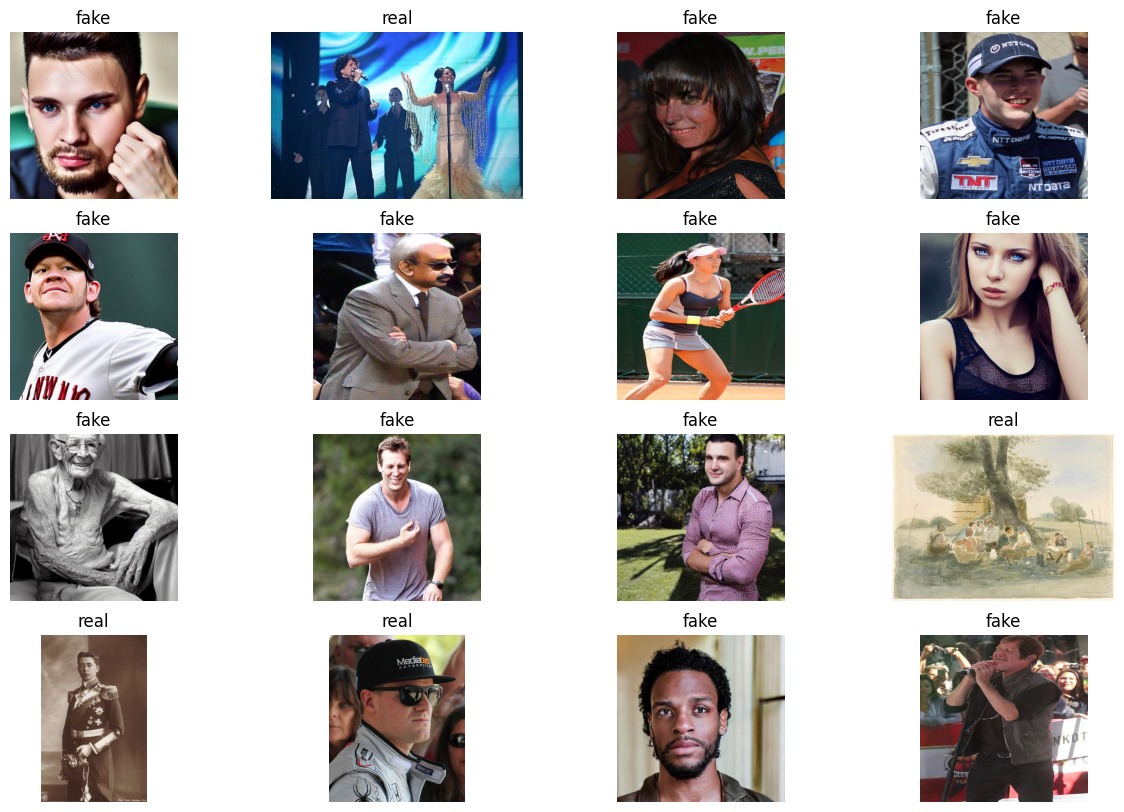

In [63]:
# %%
if in_jupyter:
    # look at a few random images
    fig, axes = plt.subplots(4, 4, figsize=(15, 10))
    for i, ax in enumerate(axes.flat):
        image_path = dataset_df.sample()["image_path"].values[0]
        image_type = dataset_df[dataset_df["image_path"] == image_path][
            "image_type"
        ].values[0]
        image = Image.open(image_path)
        ax.imshow(image)
        ax.axis("off")
        ax.set_title(f"{image_type}")
    plt.show()

In [64]:
# %%
# save the dataset DataFrame to a csv file
os.makedirs(os.path.join(path_to_root, "data"), exist_ok=True)
dataset_df.to_csv(os.path.join(path_to_root, "data/dataset.csv"), index=False)
